# Crypto Lab 08 — Elliptic Curve Cryptography

**CYBR 3570: Applied Cryptography**  
**Topic:** Elliptic curves, finite fields, ECDLP, ECDH, ECDSA risks, and curve validation

## Today's big question

> Why does ECC give us strong public-key cryptography with much smaller keys, and what can go wrong if we use it incorrectly?

This notebook is an educational exploration. We will use small toy curves so the math is visible. These examples are **not secure** and should never be used for real cryptography.

## Learning Objectives

By the end of this notebook, you should be able to:

1. Explain why ECC works over finite fields.
2. Identify points on a toy elliptic curve.
3. Implement point addition and scalar multiplication for a small curve.
4. Explain the elliptic curve discrete logarithm problem.
5. Demonstrate a toy ECDH exchange.
6. Explain why ECDSA nonce reuse is dangerous.
7. Explain why validating curve points matters.
8. Connect ECC design choices to secure engineering practices.

## Setup

In [1]:
import math
from dataclasses import dataclass
from typing import Optional, List, Tuple
import matplotlib.pyplot as plt

print("Elliptic curve lab setup complete")

Elliptic curve lab setup complete


## Part 1 — Elliptic curves over the real numbers

The chapter begins with elliptic curves drawn over the real numbers. A common form is:

$$y^2 = x^3 + ax + b$$

For example, the chapter uses a curve similar to:

$$y^2 = x^3 - 4x$$

Over the real numbers, this looks like a smooth curve. In cryptography, however, we use finite fields, so the picture changes dramatically.

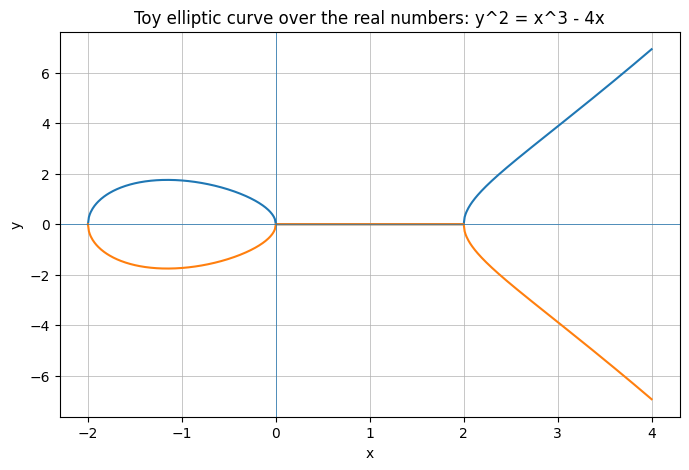

In [2]:
# Plot y^2 = x^3 - 4x over the real numbers.

xs = [x / 100 for x in range(-300, 401)]
upper_x, upper_y, lower_x, lower_y = [], [], [], []
for x in xs:
    rhs = x**3 - 4*x
    if rhs >= 0:
        y = math.sqrt(rhs)
        upper_x.append(x)
        upper_y.append(y)
        lower_x.append(x)
        lower_y.append(-y)

plt.figure(figsize=(8, 5))
plt.plot(upper_x, upper_y)
plt.plot(lower_x, lower_y)
plt.axhline(0, linewidth=0.5)
plt.axvline(0, linewidth=0.5)
plt.title("Toy elliptic curve over the real numbers: y^2 = x^3 - 4x")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, linewidth=0.5)
plt.show()

### Exercise 1

In your own words, explain why the curve is symmetric across the x-axis.

#### Answer: The curve is symmetric across the x-axis because the equation uses y*2. This means that if a positive y-value works, the negative y-value also works. So every point above the x-axis has a matching point below it.


## Part 2 — Elliptic curves over finite fields

Cryptographic elliptic curves are usually defined over a finite field such as integers modulo a prime number `p`.

For a toy curve:

$$y^2 \equiv x^3 + ax + b \pmod p$$

A point `(x, y)` belongs to the curve only if it satisfies the equation modulo `p`.

Number of affine points: 99
First 10 points: [(0, 10), (0, 87), (1, 43), (1, 54), (3, 6), (3, 91), (4, 47), (4, 50), (10, 21), (10, 76)]


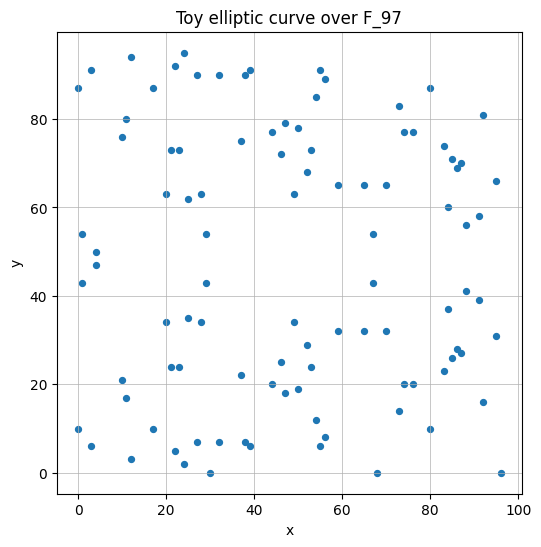

In [3]:
def curve_points(a: int, b: int, p: int) -> List[Tuple[int, int]]:
    """Return all affine points on y^2 = x^3 + ax + b mod p."""
    points = []
    for x in range(p):
        rhs = (x**3 + a*x + b) % p
        for y in range(p):
            if (y*y) % p == rhs:
                points.append((x, y))
    return points

# A small educational curve: y^2 = x^3 + 2x + 3 over F_97
a, b, p = 2, 3, 97
points = curve_points(a, b, p)
print(f"Number of affine points: {len(points)}")
print(f"First 10 points: {points[:10]}")

plt.figure(figsize=(6, 6))
plt.scatter([x for x, y in points], [y for x, y in points], s=18)
plt.title("Toy elliptic curve over F_97")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, linewidth=0.5)
plt.show()

### Exercise 2

Why does the finite-field version look like a cloud of points instead of a smooth curve?

#### Answer The finite field version looks like a cloud of points because it only uses a limited set of whole numbers instead of all real numbers. Only certain x and y values satisfy the equation, so the graph shows separate dots instead of a smooth curve.

## Part 3 — Point representation and validation

We will represent the point at infinity with `None`. The point at infinity acts like zero for elliptic curve point addition.

Before using a point, we should validate that it is actually on the curve.

In [4]:
Point = Optional[Tuple[int, int]]

@dataclass(frozen=True)
class Curve:
    a: int
    b: int
    p: int

    def contains(self, P: Point) -> bool:
        if P is None:
            return True
        x, y = P
        return (y*y - (x**3 + self.a*x + self.b)) % self.p == 0

curve = Curve(a=2, b=3, p=97)

for P in [(3, 6), (3, 91), (10, 20), None]:
    print(f"{P} on curve? {curve.contains(P)}")

(3, 6) on curve? True
(3, 91) on curve? True
(10, 20) on curve? False
None on curve? True


### Exercise 3

Find five valid points and five invalid points on the toy curve. Use the `curve.contains()` method.

In [5]:

valid_examples = [
    (0, 10),
    (0, 87),
    (1, 43),
    (1, 54),
    (3, 6)
]

invalid_examples = [
    (0, 0),
    (1, 1),
    (2, 2),
    (3, 3),
    (10, 20)
]

for P in valid_examples:
    print(P, curve.contains(P))

for P in invalid_examples:
    print(P, curve.contains(P))


(0, 10) True
(0, 87) True
(1, 43) True
(1, 54) True
(3, 6) True
(0, 0) False
(1, 1) False
(2, 2) False
(3, 3) False
(10, 20) False


## Part 4 — Modular inverses and point addition

Point addition uses division, but in a finite field division means multiplication by a modular inverse.

For example:

$$
rac{a}{b} \pmod p = a \cdot b^{-1} \pmod p$$

Python's built-in `pow(value, -1, p)` computes a modular inverse when it exists.

In [6]:
def inv_mod(x: int, p: int) -> int:
    """Return x^{-1} modulo p."""
    return pow(x % p, -1, p)

for x in [2, 3, 5, 10]:
    print(f"{x} inverse mod 97 = {inv_mod(x, 97)}; check: {(x * inv_mod(x, 97)) % 97}")

2 inverse mod 97 = 49; check: 1
3 inverse mod 97 = 65; check: 1
5 inverse mod 97 = 39; check: 1
10 inverse mod 97 = 68; check: 1


In [7]:
def point_neg(P: Point, curve: Curve) -> Point:
    if P is None:
        return None
    x, y = P
    return (x, (-y) % curve.p)


def point_add(P: Point, Q: Point, curve: Curve) -> Point:
    """Add two points on a short Weierstrass curve over F_p."""
    if P is None:
        return Q
    if Q is None:
        return P

    x1, y1 = P
    x2, y2 = Q
    p = curve.p

    if x1 == x2 and (y1 + y2) % p == 0:
        return None

    if P == Q:
        # Point doubling slope: m = (3x^2 + a) / (2y)
        m = ((3 * x1 * x1 + curve.a) * inv_mod(2 * y1, p)) % p
    else:
        # Distinct point slope: m = (y2 - y1) / (x2 - x1)
        m = ((y2 - y1) * inv_mod(x2 - x1, p)) % p

    x3 = (m*m - x1 - x2) % p
    y3 = (m * (x1 - x3) - y1) % p
    return (x3, y3)

P = (3, 6)
Q = (80, 10)
print("P on curve?", curve.contains(P))
print("Q on curve?", curve.contains(Q))
R = point_add(P, Q, curve)
print("P + Q =", R, "on curve?", curve.contains(R))
print("P + (-P) =", point_add(P, point_neg(P, curve), curve))

P on curve? True
Q on curve? True
P + Q = (80, 87) on curve? True
P + (-P) = None


### Exercise 4

Compute the following on the toy curve:

1. `P + Q`
2. `P + P`
3. `Q + Q`
4. `P + (-P)`

Then explain what the point at infinity represents.

In [9]:

P = (3, 6)
Q = (80, 10)

print("P + Q =", point_add(P, Q, curve))
print("P + P =", point_add(P, P, curve))
print("Q + Q =", point_add(Q, Q, curve))
print("P + (-P) =", point_add(P, point_neg(P, curve), curve))


P + Q = (80, 87)
P + P = (80, 10)
Q + Q = (3, 91)
P + (-P) = None


#### Response - What the point at infitinity represents

The point at infinity acts like zero in elliptic curve addition. When you add a point to its opposite, the result is the point at infinity. In the code, it shows up as None.

## Part 5 — Scalar multiplication

ECC uses scalar multiplication:

$$kP = P + P + \dots + P$$

This is easy to compute using double-and-add, but hard to reverse for secure curve sizes. Reversing it is the elliptic curve discrete logarithm problem.

In [10]:
def scalar_mult(k: int, P: Point, curve: Curve) -> Point:
    """Compute kP using double-and-add."""
    result: Point = None
    addend: Point = P

    while k > 0:
        if k & 1:
            result = point_add(result, addend, curve)
        addend = point_add(addend, addend, curve)
        k >>= 1
    return result

G = (3, 6)
for k in range(1, 11):
    print(f"{k}G = {scalar_mult(k, G, curve)}")

1G = (3, 6)
2G = (80, 10)
3G = (80, 87)
4G = (3, 91)
5G = None
6G = (3, 6)
7G = (80, 10)
8G = (80, 87)
9G = (3, 91)
10G = None


### Exercise 5

Choose a valid base point `G` and compute `kG` for several values of `k`. What pattern do you notice?

In [11]:

G = (3, 6)

for k in range(1, 16):
    print(f"{k}G = {scalar_mult(k, G, curve)}")



1G = (3, 6)
2G = (80, 10)
3G = (80, 87)
4G = (3, 91)
5G = None
6G = (3, 6)
7G = (80, 10)
8G = (80, 87)
9G = (3, 91)
10G = None
11G = (3, 6)
12G = (80, 10)
13G = (80, 87)
14G = (3, 91)
15G = None


#### Response: What pattern do you notice?

I noticed that the points repeat in a cycle. When k reaches 5, the result is None, which means the point at infinity. After that, the same points repeat again as k increases.

## Part 6 — A toy elliptic curve discrete logarithm

The ECDLP asks:

> Given `G` and `Q = kG`, find `k`.

For small toy curves, brute force works. For real curves, the group is far too large.

In [12]:
def ec_discrete_log_bruteforce(G: Point, Q: Point, curve: Curve, max_k: int = 500) -> Optional[int]:
    """Find k such that kG = Q by brute force, if k <= max_k."""
    current: Point = None
    for k in range(max_k + 1):
        if current == Q:
            return k
        current = point_add(current, G, curve)
    return None

secret_k = 17
Q = scalar_mult(secret_k, G, curve)
recovered = ec_discrete_log_bruteforce(G, Q, curve)
print("G =", G)
print("Q =", Q)
print("Recovered k =", recovered)

G = (3, 6)
Q = (80, 10)
Recovered k = 2


### Exercise 6

Create three small ECDLP examples and solve them with brute force. Then explain why this does not scale to real curves such as P-256 or Curve25519.

In [14]:

examples = [
    (2, (3, 6)),
    (3, (3, 6)),
    (4, (3, 6))
]

for k, G in examples:
    Q = scalar_mult(k, G, curve)
    recovered = ec_discrete_log_bruteforce(G, Q, curve)
    print(f"k={k}, G={G}, Q={Q}, recovered={recovered}")


k=2, G=(3, 6), Q=(80, 10), recovered=2
k=3, G=(3, 6), Q=(80, 87), recovered=3
k=4, G=(3, 6), Q=(3, 91), recovered=4


#### Response: Why does this not scale?

Brute force works on small elliptic curves because there are only a few possible values to check. Real curves like P-256 and Curve25519 have extremely large numbers of possible values, so checking them one by one would take way too long. That's why brute force isn't practical for real cryptography.

## Part 7 — Toy ECDH

ECDH mirrors classical Diffie-Hellman:

- Alice chooses secret `a` and sends `A = aG`.
- Bob chooses secret `b` and sends `B = bG`.
- Alice computes `aB`.
- Bob computes `bA`.
- Both obtain the same point `abG`.

In real systems, the shared point is passed into a KDF before it becomes symmetric keys.

In [15]:
G = (3, 6)
alice_secret = 13
bob_secret = 21

alice_public = scalar_mult(alice_secret, G, curve)
bob_public = scalar_mult(bob_secret, G, curve)

alice_shared = scalar_mult(alice_secret, bob_public, curve)
bob_shared = scalar_mult(bob_secret, alice_public, curve)

print("Alice public:", alice_public)
print("Bob public:", bob_public)
print("Alice shared:", alice_shared)
print("Bob shared:", bob_shared)
print("Match?", alice_shared == bob_shared)

Alice public: (80, 87)
Bob public: (3, 6)
Alice shared: (80, 87)
Bob shared: (80, 87)
Match? True


### Exercise 7

Act as an attacker against this toy ECDH exchange. Recover Alice's secret from her public key using brute force, then compute the shared secret.

Why does this attack work here but not against real ECDH with secure parameters?

In [16]:

attacker_recovered_alice = ec_discrete_log_bruteforce(G, alice_public, curve)
attacker_shared = scalar_mult(attacker_recovered_alice, bob_public, curve)

print("Recovered Alice secret:", attacker_recovered_alice)
print("Attacker shared secret:", attacker_shared)
print("Matches Alice shared:", attacker_shared == alice_shared)


Recovered Alice secret: 3
Attacker shared secret: (80, 87)
Matches Alice shared: True


#### Response:

This attack works because the toy curve is very small, so the attacker can try different numbers until they find one that works. Real ECDH uses much larger and more secure curves, which makes brute force take way too long to be practical.

## Part 8 — ECDSA nonce reuse, simplified

ECDSA requires a per-signature secret nonce `k`. If the same `k` is reused for two signatures, the private key can be recovered.

We will demonstrate the algebra with a simplified ECDSA-like equation:

$$s = k^{-1}(h + r d) \pmod n$$

If two signatures reuse the same `k` and have the same `r`, then:

$$k = (h_1 - h_2)(s_1 - s_2)^{-1} \pmod n$$

Then:

$$d = (s_1 k - h_1)r^{-1} \pmod n$$

This mirrors the real vulnerability: **bad randomness can reveal the signing key.**

In [17]:
# Toy ECDSA nonce reuse demonstration using modular arithmetic.
# This is not a full ECDSA implementation.

n = 101  # toy group order, prime for easy inverses
private_d = 37
reused_k = 19
r = 42
h1 = 12
h2 = 88

s1 = ((h1 + r * private_d) * inv_mod(reused_k, n)) % n
s2 = ((h2 + r * private_d) * inv_mod(reused_k, n)) % n

recovered_k = ((h1 - h2) * inv_mod(s1 - s2, n)) % n
recovered_d = ((s1 * recovered_k - h1) * inv_mod(r, n)) % n

print("s1 =", s1)
print("s2 =", s2)
print("Recovered k =", recovered_k)
print("Recovered private key d =", recovered_d)
print("Success?", recovered_d == private_d)

s1 = 8
s2 = 12
Recovered k = 19
Recovered private key d = 37
Success? True


### Exercise 8

In 3-5 sentences, explain why deterministic signature schemes such as Ed25519 help reduce this specific risk.

#### Response:


Deterministic signature schemes like Ed25519 help reduce this risk because they don't need a new random nonce for every signature. Instead, the nonce is calculated using the private key and the message. This helps prevent mistakes caused by weak randomness or accidentally reusing the same nonce for different messages. It makes signing safer because reusing a nonce can expose the private key.

## Part 9 — Point validation and invalid curve attacks

If a system accepts a public point that is not actually on the intended curve, an attacker may trick it into computing with a weak curve or small subgroup.

This is why cryptographic libraries must validate public keys and points.

In [18]:
candidate_points = [(3, 6), (80, 10), (10, 20), (0, 10), None]

for candidate in candidate_points:
    print(f"{candidate}: valid? {curve.contains(candidate)}")

(3, 6): valid? True
(80, 10): valid? True
(10, 20): valid? False
(0, 10): valid? True
None: valid? True


### Exercise 9

Write a short validation policy for ECDH public keys. What should an implementation check before using another party's public key?

#### Response:

Before using another person's public key, the system should check that the point is actually on the correct elliptic curve. It should also make sure the point is not the point at infinity and that it belongs to the correct subgroup. This helps prevent attackers from using invalid or weak points to steal information.

## Engineering checkpoint

Answer the following questions. Keep each response to 2-4 sentences.

1. Why is ECC often preferred over RSA for constrained systems?

2. Why should developers avoid creating their own curves?

3. Why must ECDH shared secrets be passed through a KDF?

4. What makes ECDSA fragile compared to Ed25519?


1. ECC provides strong security with smaller keys than RSA. This makes it better for devices with limited memory and processing power.

2. Developers should avoid making their own curves because mistakes can make them insecure. Using trusted curves that experts have tested is safer.

3. A KDF turns the ECDH shared secret into a secure encryption key. It also helps create separate keys for different purposes.

4. ECDSA requires a secure nonce for every signature. If the nonce is reused or predictable, attackers could recover the private key. Ed25519 reduces this risk by generating nonces deterministically.

## Submission checklist

Before submitting, make sure you have:

- [ y] Completed all written responses.
- [ y] Run the notebook from top to bottom without errors.
- [ y] Completed the toy ECC exercises.
- [ y] Updated your engineering log.

## Final reflection

Return to today's big question:

> Why does ECC give us strong public-key cryptography with much smaller keys, and what can go wrong if we use it incorrectly?

Answer using at least two examples from the notebook.

#### Final Reflection:

ECC provides strong security with smaller keys because it uses math problems that are very difficult for attackers to solve. In Exercise 7, we saw that brute force could recover a secret key on a small curve, but this would be extremely difficult on real curves. In Exercise 8, we learned that reusing the same nonce in ECDSA can expose the private key. Exercise 9 also showed why checking public keys is important, because invalid points can lead to attacks. This shows that ECC is secure when used correctly, but mistakes can put private keys and information at risk.